# Mudanças de especificação inacabadas no OpenSpec
## 02 — Tabela de mudanças no censo completo e estados do ciclo de vida (OM1)

Segunda etapa do processo KDD: pré-processamento e transformação. Monta a **tabela de mineração** (uma linha por mudança OpenSpec)
para o censo completo do SpecMine e estima a frequência de cada estado do ciclo de vida, respondendo à primeira metade da pergunta
de pesquisa: *com que frequência mudanças de especificação OpenSpec ficam inacabadas?*

A construção da tabela e as regras de estado estão em `src/openspec_changes.py`, as mesmas usadas no protótipo do notebook 01.

**Convenção:** **[Fato]** = observado nos dados · **[Interpretação]** = nossa leitura · **[Hipótese]** = a testar.

## 1. Estados refinados

O protótipo do notebook 01 mostrou que 40% das mudanças ativas paradas têm **todas as tarefas marcadas e nunca foram arquivadas**.
Esse caso é uma falha de fechamento, não de execução, e ganha um estado próprio. Para um limiar de inatividade *T* (dias):

| Estado | Condição | Grupo |
|---|---|---|
| completed | arquivada, todas as tarefas marcadas | concluída |
| completed with pending tasks | arquivada, ao menos uma tarefa desmarcada | **potencialmente inacabada** |
| archived without task counts | arquivada, sem tarefas contáveis | concluída (sem contagem) |
| in progress | ativa, último commit há menos de *T* dias | censurada |
| done, not archived | ativa, parada há ≥ *T* dias, todas as tarefas marcadas | **não fechada** |
| overtaken | ativa, parada há ≥ *T* dias, com pendências, e o repositório arquivou outra mudança depois | **potencialmente inacabada** |
| stalled | ativa, parada há ≥ *T* dias, com pendências, e o repositório não arquivou nada depois | **potencialmente inacabada** |
| stopped without task counts | ativa, parada há ≥ *T* dias, sem tarefas contáveis | outro |
| undated | ativa, sem *spec delta* datado | outro |

"Parada" é medida pelo último commit nos *spec deltas* da mudança, até o fim do crawl de commits (2026-07-11).

## 2. Configuração

In [1]:
from pathlib import Path
import json, os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display

pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 80)

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from openspec_changes import (RX_CHANGE, STATES, POTENTIALLY_UNFINISHED, UNCLOSED, PENDING_CATEGORIES, UNCATEGORIZED,
                              change_dir, build_change_table, pending_items, assign_states)

SAMPLE_DIR = Path(os.environ.get('SPECMINE_SAMPLE', ROOT.parent / 'specmine-official'))
CACHE = ROOT / 'data_cache'; CACHE.mkdir(exist_ok=True)
OUT = ROOT / 'outputs' / '02_change_table'; FIG = OUT / 'figures'; TAB = OUT / 'tables'
for p in (FIG, TAB): p.mkdir(parents=True, exist_ok=True)

SEED = 20260711
OBS_END = pd.Timestamp('2026-07-11 23:59:59', tz='UTC')
THRESHOLDS = [30, 60, 90]
MAIN_T = 30
R = {}

C = dict(blue='#2a78d6', orange='#eb6834', aqua='#1baf7a', yellow='#eda100', gray='#8c8b86',
         light='#d9d8d2', ink='#0b0b0b', ink2='#52514e')
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 9, 'axes.titlesize': 10, 'axes.labelsize': 9,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e5e0',
    'grid.linewidth': 0.6, 'axes.axisbelow': True, 'axes.edgecolor': C['gray'], 'xtick.color': C['ink2'],
    'ytick.color': C['ink2'], 'legend.frameon': False, 'figure.facecolor': 'white', 'lines.linewidth': 2})

def dt(x):  return pd.to_datetime(x, utc=True, errors='coerce')
def pct(x): return round(100 * float(np.mean(x)), 2) if len(x) else np.nan

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f'{name}.png', bbox_inches='tight'); fig.savefig(FIG / f'{name}.pdf', bbox_inches='tight')
    plt.show(); plt.close(fig)

def save_table(df, name, index=False):
    df.to_csv(TAB / f'{name}.csv', index=index); return df

def cluster_boot(df, flag, cluster='repo_name', B=2000, seed=SEED):
    g = df.groupby(cluster)[flag].agg(['sum', 'count'])
    rng = np.random.default_rng(seed); idx = rng.integers(0, len(g), size=(B, len(g)))
    s = g['sum'].to_numpy()[idx].sum(1); n = g['count'].to_numpy()[idx].sum(1)
    lo, hi = np.percentile(s / n, [2.5, 97.5])
    return {'n': int(g['count'].sum()), 'repos': len(g), 'pct': round(100 * g['sum'].sum() / g['count'].sum(), 1),
            'ci95': f'[{100 * lo:.1f}, {100 * hi:.1f}]', 'repo_macro_pct': round(100 * (g['sum'] / g['count']).mean(), 1)}
print('pandas', pd.__version__)

pandas 3.0.6


## 3. Dados do censo completo

Baixados por `scripts/download_data.py` do mirror do SpecMine no Hugging Face (só as colunas e linhas necessárias, cerca de
140 MB) e guardados em `data_cache/`, que não é versionado.

| Arquivo em cache | Origem | Conteúdo |
|---|---|---|
| `full_openspec_artifacts_meta` | `openspec_artifact_files` | todos os artefatos, sem o texto |
| `full_openspec_tasks_content` | `openspec_artifact_files` | texto dos `tasks.md` (para classificar pendências) |
| `full_openspec_code_refs` | `openspec_code_refs` | referências das tarefas a arquivos de código |
| `full_active_delta_commits` | `spec_file_commits` | commits dos *spec deltas* de mudanças ativas (`openspec/changes/`, fora de `archive/`) |
| `full_spec_files_slim` | `spec_files` | 13 colunas de todas as specs |

In [2]:
def load_cache(name):
    path = CACHE / f'{name}.parquet'
    if not path.exists():
        raise FileNotFoundError(f'{path} não existe: rode `python scripts/download_data.py` antes (ver README)')
    return pd.read_parquet(path)

art = load_cache('full_openspec_artifacts_meta')
tasks_txt = load_cache('full_openspec_tasks_content')
refs = load_cache('full_openspec_code_refs')
commits = load_cache('full_active_delta_commits')
slim = load_cache('full_spec_files_slim')
inv = pd.DataFrame([(n, len(d), d.repo_name.nunique()) for n, d in
                    [('artifacts (meta)', art), ('tasks.md content', tasks_txt), ('code refs', refs),
                     ('active delta commits', commits), ('spec_files (slim)', slim)]],
                   columns=['table', 'rows', 'repos'])
display(save_table(inv, '01_inventory'))

,table,rows,repos
0,artifacts (meta),266230,8366
1,tasks.md content,93061,8321
2,code refs,435401,7076
3,active delta commits,50266,5362
4,spec_files (slim),470795,73031


## 4. Sanidade

In [3]:
art['change_dir'] = change_dir(art.file_path)
os_spec = slim[slim.spec_tool.eq('openspec')]
sanity = pd.DataFrame([
    ('artifacts: fetch_status ≠ done', int(art.fetch_status.ne('done').sum())),
    ('artifacts: outside openspec/changes/', int(art.change_dir.isna().sum())),
    ('artifacts: duplicated (repo, path)', int(art.duplicated(['repo_name', 'file_path']).sum())),
    ('artifacts: n_tasks_done > n_tasks', int((art.n_tasks_done > art.n_tasks).sum())),
    ('artifacts: tasks.md without counts', int(art.loc[art.kind.eq('tasks.md'), 'n_tasks'].isna().sum())),
    ('artifacts: fetched_at range', f'{art.fetched_at.min()} → {art.fetched_at.max()}'),
    ('OpenSpec specs: commit_history_status ≠ done', int(os_spec.commit_history_status.ne('done').sum())),
    ('OpenSpec specs: duplicated (repo, path) rows', int(os_spec.duplicated(['repo_name', 'file_path']).sum())),
    ('OpenSpec specs: forks / archived repos', f'{int(os_spec.repo_fork.eq(1).sum())} / {int(os_spec.repo_archived.eq(1).sum())}'),
    ('active delta commits: committed_at range', f'{dt(commits.committed_at).min():%Y-%m-%d} → {dt(commits.committed_at).max():%Y-%m-%d}'),
    ('active delta commits: after OBS_END', int((dt(commits.committed_at) > OBS_END).sum())),
], columns=['check', 'result'])
sanity['result'] = sanity.result.astype(str)
display(save_table(sanity, '02_sanity'))

,check,result
0,artifacts: fetch_status ≠ done,1689
1,artifacts: outside openspec/changes/,3367
2,"artifacts: duplicated (repo, path)",0
3,artifacts: n_tasks_done > n_tasks,0
4,artifacts: tasks.md without counts,586
5,artifacts: fetched_at range,2026-07-20T22:47:26Z → 2026-07-21T16:48:12Z
6,OpenSpec specs: commit_history_status ≠ done,937
7,"OpenSpec specs: duplicated (repo, path) rows",15136
8,OpenSpec specs: forks / archived repos,0 / 0
9,active delta commits: committed_at range,2025-09-15 → 2026-07-11


### 4.1 Spec deltas e suas datas

Deduplicamos as specs por `(repo_name, file_path)`, como no notebook 01. Para mudanças ativas, as datas vêm dos commits
(`committed_at`); para mudanças arquivadas não são necessárias (o histórico anterior ao arquivamento não existe no dataset).

In [4]:
deltas = (os_spec[os_spec.spec_role.isin(['change_proposal', 'archived']) & os_spec.commit_history_status.eq('done')]
          .sort_values('file_url_sha16').drop_duplicates(['repo_name', 'file_path']))
ev = commits.assign(t=dt(commits.committed_at))
ev = ev[ev.t.le(OBS_END)]
per = ev.groupby('file_url_sha16').agg(first=('t', 'min'), last=('t', 'max'))
deltas = deltas.merge(per, on='file_url_sha16', how='left')
cp = deltas[deltas.spec_role.eq('change_proposal')]
print(f"Spec deltas: {len(deltas):,} (change_proposal {len(cp):,}, archived {int(deltas.spec_role.eq('archived').sum()):,}); "
      f"change_proposal com data: {pct(cp['last'].notna())}%")

Spec deltas: 186,341 (change_proposal 39,740, archived 146,601); change_proposal com data: 99.98%


## 5. Validação: o censo restrito à amostra reproduz o notebook 01?

A amostra oficial é uma fatia do censo. Restringindo o censo aos 500 repositórios da amostra, a tabela de mudanças deve coincidir
com a do notebook 01.

In [5]:
sample_repos = set(Path(SAMPLE_DIR / 'sample_repos.txt').read_text(encoding='utf-8').split())
ch_s = build_change_table(art[art.repo_name.isin(sample_repos)], refs[refs.repo_name.isin(sample_repos)],
                          deltas[deltas.repo_name.isin(sample_repos)], OBS_END)
nb01 = json.loads((ROOT / 'outputs' / '01_data_understanding' / 'key_numbers.json').read_text(encoding='utf-8'))
w = ch_s[ch_s.n_tasks > 0]
val = pd.DataFrame([
    ('changes', nb01['changes']['total'], len(ch_s)),
    ('active changes', nb01['changes']['active'], int((~ch_s.archived).sum())),
    ('archived changes', nb01['changes']['archived'], int(ch_s.archived.sum())),
    ('repos', nb01['changes']['repos'], ch_s.repo_name.nunique()),
    ('active with pending tasks %', nb01['any_pending_active']['pct'], round(pct(w.loc[~w.archived, 'n_pending'].gt(0)), 1)),
    ('archived with pending tasks %', nb01['any_pending_archived']['pct'], round(pct(w.loc[w.archived, 'n_pending'].gt(0)), 1)),
    ('active changes with dated spec delta %', nb01['coverage']['Mudanças ativas com spec delta datado (%)'],
     pct(ch_s.loc[~ch_s.archived, 'delta_last'].notna())),
], columns=['quantity', 'notebook 01 (sample files)', 'full census restricted to sample'])
val['match'] = val.iloc[:, 1].astype(float).round(1) == val.iloc[:, 2].astype(float).round(1)
display(save_table(val, '03_validation_against_sample'))
R['validation_all_match'] = bool(val.match.all())

,quantity,notebook 01 (sample files),full census restricted to sample,match
0,changes,8174.0,8174.0,True
1,active changes,996.0,996.0,True
2,archived changes,7178.0,7178.0,True
3,repos,142.0,142.0,True
4,active with pending tasks %,60.6,60.6,True
5,archived with pending tasks %,15.6,15.6,True
6,active changes with dated spec delta %,100.0,100.0,True


## 6. Tabela de mudanças do censo completo

In [6]:
ch = build_change_table(art, refs, deltas, OBS_END)
it = pending_items(tasks_txt)
cat_cols = list(PENDING_CATEGORIES) + [UNCATEGORIZED]
pc = it.groupby(['repo_name', 'change_dir'])[cat_cols].sum()
pc.columns = ['pend_' + c.split(' ')[0].replace('/', '').lower() for c in cat_cols]
ch = ch.merge(pc, on=['repo_name', 'change_dir'], how='left')
for c_ in pc.columns: ch[c_] = ch[c_].fillna(0).astype(int)
R['changes'] = {'total': len(ch), 'active': int((~ch.archived).sum()), 'archived': int(ch.archived.sum()),
                'repos': ch.repo_name.nunique()}
print(f"Mudanças: {len(ch):,} em {ch.repo_name.nunique():,} repositórios — ativas {R['changes']['active']:,}, "
      f"arquivadas {R['changes']['archived']:,}")
per_repo = ch.groupby('repo_name').size()
prof = pd.DataFrame([
    ('changes per repo — median', per_repo.median()), ('changes per repo — p90', per_repo.quantile(.9)),
    ('changes per repo — max', per_repo.max()),
    ('share of changes in the 10 largest repos %', round(100 * per_repo.nlargest(10).sum() / len(ch), 1)),
    ('repos with a single change %', pct(per_repo.eq(1))),
    ('repos that never archived a change %', pct(~ch.groupby('repo_name').archived.any())),
    ('active changes with dated spec delta %', pct(ch.loc[~ch.archived, 'delta_last'].notna())),
    ('archived changes with spec delta %', pct(ch.loc[ch.archived, 'n_spec_deltas'].gt(0))),
    ('changes without tasks.md %', pct(~ch.has_tasks)),
    ('changes without proposal.md %', pct(~ch.has_proposal)),
], columns=['indicator', 'value'])
display(save_table(prof, '04_change_table_profile'))
R['profile'] = dict(zip(prof.indicator, prof.value))

Mudanças: 91,736 em 8,301 repositórios — ativas 19,009, arquivadas 72,727


,indicator,value
0,changes per repo — median,4.00
1,changes per repo — p90,24.00
2,changes per repo — max,1262.00
3,share of changes in the 10 largest repos %,6.10
4,repos with a single change %,27.15
5,repos that never archived a change %,29.25
6,active changes with dated spec delta %,99.84
7,archived changes with spec delta %,99.83
8,changes without tasks.md %,0.72
9,changes without proposal.md %,0.36


## 7. Com que frequência as mudanças ficam inacabadas? (OM1)

In [7]:
rows = []
for T in THRESHOLDS:
    st = pd.Series(assign_states(ch, T), index=ch.index)
    cnt = st.value_counts().reindex(STATES, fill_value=0)
    row = {'T_days': T, **{f'{s} (n)': int(v) for s, v in cnt.items()}}
    row['potentially unfinished, % of all changes'] = pct(st.isin(POTENTIALLY_UNFINISHED))
    row['not closed, % of all changes'] = pct(st.isin(UNCLOSED))
    a_ = st[~ch.archived]
    for s in ['in progress', 'done, not archived', 'overtaken', 'stalled']:
        row[f'active: {s} %'] = pct(a_.eq(s))
    rows.append(row)
states = save_table(pd.DataFrame(rows), '05_states_by_threshold')
display(states.set_index('T_days').T)
ch['state'] = assign_states(ch, MAIN_T)
R['states_by_T'] = states.set_index('T_days').to_dict('index')

T_days,30,60,90
completed (n),59096.00,59096.00,59096.00
completed with pending tasks (n),12265.00,12265.00,12265.00
archived without task counts (n),1366.00,1366.00,1366.00
in progress (n),4339.00,8637.00,11634.00
"done, not archived (n)",6649.00,4605.00,3124.00
overtaken (n),2368.00,1656.00,1181.00
stalled (n),5074.00,3740.00,2807.00
stopped without task counts (n),548.00,340.00,232.00
undated (n),31.00,31.00,31.00
"potentially unfinished, % of all changes",21.48,19.25,17.72


In [8]:
# Números principais (T = 30), com IC 95% por bootstrap de repositórios
x = ch.assign(unf=ch.state.isin(POTENTIALLY_UNFINISHED).astype(int), unc=ch.state.isin(UNCLOSED).astype(int))
arc_t = ch[ch.archived & ch.n_tasks.gt(0)].assign(f=lambda d: d.n_pending.gt(0).astype(int))
act_stop = ch[~ch.archived & ch.idle_days.ge(MAIN_T) & ch.n_tasks.gt(0)]
head = {
    'potentially unfinished (all changes)': cluster_boot(x, 'unf'),
    'not closed (all changes)': cluster_boot(x, 'unc'),
    'archived with pending tasks (archived changes with tasks)': cluster_boot(arc_t, 'f'),
    'done, not archived (stopped active changes with tasks)': cluster_boot(act_stop.assign(f=act_stop.n_pending.eq(0).astype(int)), 'f'),
}
repo_any = x.groupby('repo_name').agg(unf=('unf', 'max'), unc=('unc', 'max'))
head_tab = pd.DataFrame(head).T
display(save_table(head_tab, '06_headline_T30', index=True))
print(f"Repositórios com ao menos uma mudança potencialmente inacabada: {pct(repo_any.unf)}%; "
      f"com ao menos uma não fechada: {pct(repo_any.unc)}%")
R['headline_T30'] = head; R['repos_with_unfinished_pct'] = pct(repo_any.unf); R['repos_with_unclosed_pct'] = pct(repo_any.unc)

# Robustez: sem os 10 maiores repositórios; e só repositórios que já arquivaram alguma mudança
big = per_repo.nlargest(10).index
ever_arch = ch.groupby('repo_name').archived.any()
rob = pd.DataFrame({
    'all repos': [pct(x.unf), pct(x.unc)],
    'without 10 largest repos': [pct(x.loc[~x.repo_name.isin(big), 'unf']), pct(x.loc[~x.repo_name.isin(big), 'unc'])],
    'repos that archived at least once': [pct(x.loc[x.repo_name.map(ever_arch), 'unf']), pct(x.loc[x.repo_name.map(ever_arch), 'unc'])],
}, index=['potentially unfinished %', 'not closed %'])
display(save_table(rob, '07_robustness_T30', index=True))
R['robustness_T30'] = rob.to_dict()

,n,repos,pct,ci95,repo_macro_pct
potentially unfinished (all changes),91736,8301,21.5,"[20.4, 22.5]",28.8
not closed (all changes),91736,8301,7.2,"[6.6, 8.0]",13.5
archived with pending tasks (archived changes with tasks),71361,5812,17.2,"[16.1, 18.3]",19.7
"done, not archived (stopped active changes with tasks)",14091,3925,47.2,"[44.9, 49.3]",43.3


Repositórios com ao menos uma mudança potencialmente inacabada: 55.97%; com ao menos uma não fechada: 26.41%


,all repos,without 10 largest repos,repos that archived at least once
potentially unfinished %,21.48,21.92,19.77
not closed %,7.25,7.59,4.45


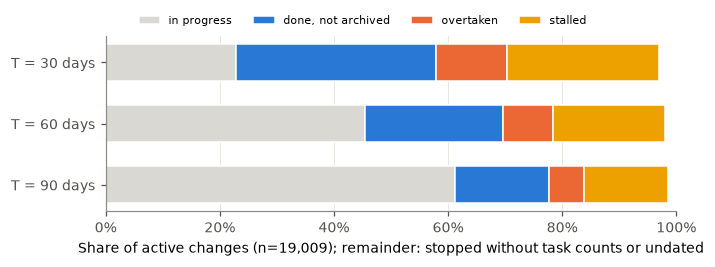

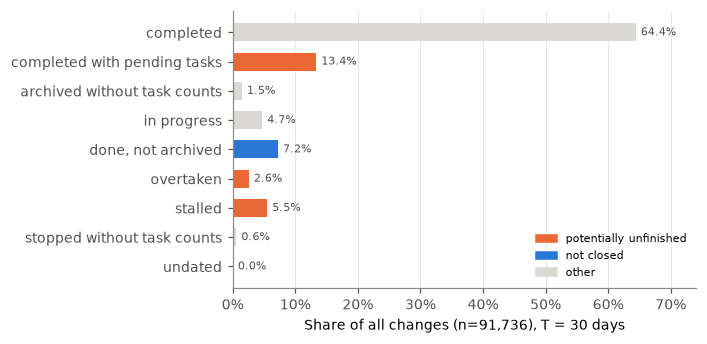

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 2.5))
parts = [('active: in progress %', C['light'], 'in progress'), ('active: done, not archived %', C['blue'], 'done, not archived'),
         ('active: overtaken %', C['orange'], 'overtaken'), ('active: stalled %', C['yellow'], 'stalled')]
left = np.zeros(len(states)); ylab = [f'T = {t} days' for t in states.T_days]
for col, colr, lab in parts:
    v = (states[col] / 100).to_numpy()
    ax.barh(ylab, v, left=left, color=colr, label=lab, height=0.6, edgecolor='white', linewidth=1); left += v
ax.invert_yaxis(); ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.grid(axis='y', visible=False); ax.set_xlim(0, 1)
ax.set_xlabel(f"Share of active changes (n={R['changes']['active']:,}); remainder: stopped without task counts or undated")
ax.legend(fontsize=7, ncol=4, loc='lower center', bbox_to_anchor=(0.45, 1.0))
savefig(fig, 'F01_active_change_states_by_threshold')

order = ['completed', 'completed with pending tasks', 'archived without task counts', 'in progress',
         'done, not archived', 'overtaken', 'stalled', 'stopped without task counts', 'undated']
share = ch.state.value_counts(normalize=True).reindex(order, fill_value=0)
colors = [C['orange'] if s in POTENTIALLY_UNFINISHED else C['blue'] if s in UNCLOSED else C['light'] for s in order]
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.barh(order, share.values, color=colors, height=0.62)
for y, v in enumerate(share.values):
    ax.text(v + 0.008, y, f'{100 * v:.1f}%', va='center', fontsize=7.5, color=C['ink2'])
ax.invert_yaxis(); ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.grid(axis='y', visible=False)
ax.set_xlim(0, max(share.values) * 1.15)
ax.set_xlabel(f"Share of all changes (n={len(ch):,}), T = {MAIN_T} days")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=C['orange'], label='potentially unfinished'), Patch(color=C['blue'], label='not closed'),
                   Patch(color=C['light'], label='other')], fontsize=7, loc='lower right')
savefig(fig, 'F02_change_states_T30')

## 8. O que fica pendente (censo completo)

archived,active,archived
manual verification / QA,12.9,14.8
automated tests,15.6,19.0
documentation,3.5,3.4
deploy / release / ops,3.5,4.2
optional / follow-up,1.5,3.1
OpenSpec housekeeping,1.9,3.7
uncategorized (likely implementation),67.4,61.8
unchecked items (n),227301.0,144890.0


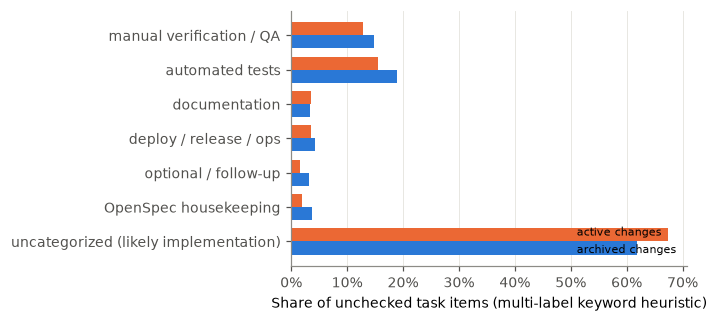

In [10]:
g_it = it.archived.map({True: 'archived', False: 'active'})
cat_tab = (100 * it.groupby(g_it)[cat_cols].mean()).round(1).T
cat_tab.loc['unchecked items (n)'] = it.groupby(g_it).size()
display(save_table(cat_tab, '08_pending_item_categories', index=True))
R['pending_categories'] = cat_tab.to_dict()

plot = cat_tab.drop(index='unchecked items (n)')
fig, ax = plt.subplots(figsize=(6.5, 3.0)); y = np.arange(len(plot)); h = 0.38
ax.barh(y - h / 2, plot['active'] / 100, height=h, color=C['orange'], label='active changes')
ax.barh(y + h / 2, plot['archived'] / 100, height=h, color=C['blue'], label='archived changes')
ax.set_yticks(y); ax.set_yticklabels(plot.index); ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.grid(axis='y', visible=False)
ax.set_xlabel('Share of unchecked task items (multi-label keyword heuristic)'); ax.legend(fontsize=7.5, loc='lower right')
savefig(fig, 'F03_pending_item_categories')

## 9. Atributos para a mineração (OM2 e OM3)

Atributos de conteúdo, disponíveis igualmente para mudanças ativas e arquivadas. Medianas por estado (T = 30 dias).

In [11]:
FEATS = ['n_tasks', 'completion', 'n_pending', 'proposal_bytes', 'n_spec_deltas', 'n_code_refs', 'repo_n_changes']
order_s = ['completed', 'completed with pending tasks', 'in progress', 'done, not archived', 'overtaken', 'stalled']
desc = ch[ch.state.isin(order_s)].groupby('state')[FEATS].median().reindex(order_s).round(2)
desc['has_design %'] = ch.groupby('state').has_design.mean().reindex(order_s).mul(100).round(1)
desc['changes (n)'] = ch.state.value_counts().reindex(order_s)
desc['repos (n)'] = ch.groupby('state').repo_name.nunique().reindex(order_s)
display(save_table(desc, '09_features_by_state', index=True))
miss = ch[FEATS + ['has_design', 'code_refs_exist_pct']].isna().mean().mul(100).round(1).rename('missing %').to_frame().T
display(miss)
corr = ch[FEATS].corr(method='spearman').round(2)
display(save_table(corr, '10_feature_correlation', index=True))

,n_tasks,completion,n_pending,proposal_bytes,n_spec_deltas,n_code_refs,repo_n_changes,has_design %,changes (n),repos (n)
state,,,,,,,,,,
completed,15.0,1.00,0.0,2141.0,1.0,2.0,38.0,87.4,59096,5363
completed with pending tasks,25.0,0.82,4.0,2941.0,1.0,4.0,35.0,84.3,12265,2748
in progress,17.0,1.00,0.0,2696.0,1.0,2.0,23.0,82.0,4339,1177
"done, not archived",15.0,1.00,0.0,1816.0,1.0,1.0,14.0,84.3,6649,2192
overtaken,23.0,0.00,12.0,2562.0,1.0,2.0,30.5,82.7,2368,655
stalled,26.0,0.31,10.0,2337.0,1.0,2.0,8.0,81.0,5074,2254


,n_tasks,completion,n_pending,proposal_bytes,n_spec_deltas,n_code_refs,repo_n_changes,has_design,code_refs_exist_pct
missing %,0.7,2.4,2.4,0.4,0.0,0.0,0.0,0.0,33.9


,n_tasks,completion,n_pending,proposal_bytes,n_spec_deltas,n_code_refs,repo_n_changes
n_tasks,1.00,-0.22,0.26,0.56,0.35,0.43,-0.13
completion,-0.22,1.00,-1.00,-0.16,0.00,-0.10,0.11
n_pending,0.26,-1.00,1.00,0.18,0.02,0.12,-0.12
proposal_bytes,0.56,-0.16,0.18,1.00,0.29,0.44,0.03
n_spec_deltas,0.35,0.00,0.02,0.29,1.00,0.17,-0.05
n_code_refs,0.43,-0.10,0.12,0.44,0.17,1.00,-0.05
repo_n_changes,-0.13,0.11,-0.12,0.03,-0.05,-0.05,1.00


In [12]:
# Exporta a tabela de mineração (sem texto): entrada do notebook 03
keep = ['repo_name', 'change_dir', 'archived', 'archive_date', 'state', 'has_proposal', 'has_design', 'has_tasks',
        'n_artifacts', 'n_tasks', 'n_done', 'n_pending', 'completion', 'proposal_bytes', 'n_spec_deltas',
        'n_code_refs', 'code_refs_exist_pct', 'repo_n_changes', 'delta_first', 'delta_last', 'idle_days',
        'later_archive'] + list(pc.columns)
ch[keep].to_parquet(OUT / 'change_table.parquet', index=False, compression='zstd')
print(f"change_table.parquet: {len(ch):,} linhas × {len(keep)} colunas, "
      f"{(OUT / 'change_table.parquet').stat().st_size / 1e6:.1f} MB")

change_table.parquet: 91,736 linhas × 29 colunas, 2.7 MB


## 10. Síntese

**[Fato] A tabela.** O censo tem 91.736 mudanças OpenSpec em 8.301 repositórios (19.009 ativas, 72.727 arquivadas). Restrita aos 500 repositórios da amostra, a construção reproduz exatamente os números do notebook 01. Ao contrário da amostra, a distribuição não é dominada por poucos projetos: mediana de 4 mudanças por repositório, e os 10 maiores somam só 6,1% das mudanças. 29,3% dos repositórios nunca arquivaram uma mudança.

**[Fato] Resposta à primeira metade da pergunta** (T = 30 dias, IC 95% por *bootstrap* de repositórios):

- **21,5%** das mudanças são potencialmente inacabadas (IC 20,4–22,5). Média por repositório: 28,8%.
- **7,2%** não foram fechadas: têm todas as tarefas marcadas, estão paradas e nunca foram arquivadas (IC 6,6–8,0).
- **17,2%** das mudanças arquivadas foram fechadas com tarefas desmarcadas (IC 16,1–18,3).
- **47,2%** das mudanças ativas paradas estão "feitas, não arquivadas" (IC 44,9–49,3).
- **56,0%** dos repositórios têm ao menos uma mudança potencialmente inacabada, e 26,4% têm ao menos uma não fechada.

**[Fato] Robustez.** A taxa de potencialmente inacabadas varia pouco com o limiar (21,5% com T = 30; 19,3% com T = 60; 17,7% com T = 90), porque a maior parte vem das arquivadas com pendências, que não dependem de *T*. A taxa também quase não muda sem os 10 maiores repositórios (21,9%), e cai para 19,8% entre repositórios que já arquivaram alguma mudança.

**[Fato] Os estados têm perfis distintos** (medianas):

- Mudanças **ultrapassadas** têm completude 0: em geral nenhuma tarefa foi marcada, com 12 pendências.
- Mudanças **paradas** têm completude 0,31 e estão em repositórios muito pequenos (8 mudanças, contra 30 a 38 nos outros estados).
- **Arquivadas com pendências** são maiores que as concluídas: 25 tarefas contra 15; proposta de 2,9 kB contra 2,1 kB; 4 referências a código contra 2.
- **Feitas e não arquivadas** são pequenas (15 tarefas, proposta de 1,8 kB) e estão em repositórios pequenos (14 mudanças).

**[Fato] Pendências.** Em 372 mil itens desmarcados, a maioria não cai em categorias periféricas (67,4% nas ativas, 61,8% nas arquivadas). Testes (19,0% contra 15,6%) e verificação manual (14,8% contra 12,9%) são um pouco mais frequentes nas arquivadas.

**[Interpretação]**

1. Cerca de uma em cada cinco mudanças fica potencialmente inacabada, e o resultado é estável entre limiares e sem os maiores projetos. Isso responde à primeira metade da pergunta de pesquisa.
2. Há três formas distintas de "não terminar", com perfis diferentes: **nunca começada** (ultrapassada, sem tarefas marcadas), **abandonada no meio** (parada, em repositórios pequenos, possivelmente dormentes) e **fechada sem verificar** (arquivada com pendências, em mudanças maiores). Somam-se a elas as **feitas mas não fechadas**. Essa diferença é um bom indício de que a mineração (OM2, OM3) vai encontrar padrões.
3. "Parada" aparece em repositórios muito pequenos, o que é compatível com a dormência do repositório inteiro observada no ciclo 1. O tamanho do repositório precisa entrar como atributo ou controle.

**[Interpretação] Implicações para a mineração.**

- `completion` e `n_pending` são redundantes entre si (Spearman −1), e definem os próprios estados. Para explicar o estado, a mineração deve usar atributos que **não** sejam a contagem de tarefas: tamanho da proposta, `design.md`, *spec deltas*, referências a código, tipo das pendências e tamanho do repositório. Caso contrário, as regras ficariam circulares.
- `code_refs_exist_pct` falta em 33,9% das mudanças (as que não citam código): usar `n_code_refs` ou discretizar com uma categoria "sem referências".
- A tabela de mineração está em `outputs/02_change_table/change_table.parquet` (91.736 linhas × 29 colunas, 2,7 MB) e é a entrada do notebook 03.

In [13]:
def to_jsonable(o):
    if isinstance(o, dict): return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_jsonable(v) for v in o]
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, (np.floating, float)): return None if np.isnan(o) else round(float(o), 4)
    if isinstance(o, np.bool_): return bool(o)
    return o
(OUT / 'key_numbers.json').write_text(json.dumps(to_jsonable(R), indent=2, ensure_ascii=False), encoding='utf-8')
print('Figuras:', sorted(p.name for p in FIG.glob('*.png')))
print('Tabelas:', sorted(p.name for p in TAB.glob('*.csv')))

Figuras: ['F01_active_change_states_by_threshold.png', 'F02_change_states_T30.png', 'F03_pending_item_categories.png']
Tabelas: ['01_inventory.csv', '02_sanity.csv', '03_validation_against_sample.csv', '04_change_table_profile.csv', '05_states_by_threshold.csv', '06_headline_T30.csv', '07_robustness_T30.csv', '08_pending_item_categories.csv', '09_features_by_state.csv', '10_feature_correlation.csv']
